# Part 2.2 — Logistic Regression
**Dataset:** 6-class Emotion Classification.

**Goal:** Implement binary **bigram** features and **multiclass softmax logistic regression from scratch using NumPy**, train with shuffled mini-batches/SGD, and compare against scikit-learn `LogisticRegression` and `SGDClassifier`.

**Shared split:** 80% train / 10% validation / 10% test, `SEED=42`, stratified. Build the bigram vocabulary from **train, validation, and test texts** as requested. Labels are not used to build features. Do not touch test labels while tuning models.

## 1. Setup

In [8]:
from pathlib import Path
import sys

# Support launching Jupyter from the repo root or notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import lil_array
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import log_loss
from utils.data_loader import load_emotion_splits
from utils.preprocessing import tokenize
from utils.evaluation import sklearn_evaluation

## 2. Load and preprocess the shared 80/10/10 dataset
Student 2 uses **exactly the same** `load_emotion_splits(seed=42)` function.

Remove stopwords before constructing bigrams in each split.

In [10]:
data = load_emotion_splits(seed=SEED)

print(f"Train example: {data.train.texts[0]} \nlabel: {data.class_names[data.train.labels[0]]}")

train_tokens = [tokenize(text, remove_stopwords=True) for text in data.train.texts]
val_tokens = [tokenize(text, remove_stopwords=True) for text in data.val.texts]
test_tokens = [tokenize(text, remove_stopwords=True) for text in data.test.texts]

print('Example:', train_tokens[0], '\n', 'label:', data.class_names[data.train.labels[0]])

Train example: i feel excelent but sometimes theres just nothing to do especially since im not really keen on video games anymore i watch a bit of anime and some movies but theres just got to be more in my life 
label: joy
Example: ['feel', 'excelent', 'sometimes', 'theres', 'nothing', 'especially', 'since', 'im', 'not', 'really', 'keen', 'video', 'games', 'anymore', 'watch', 'bit', 'anime', 'movies', 'theres', 'got', 'life'] 
 label: joy


## 3. Binary Bigram Features

We build a vocabulary of unique bigrams from the preprocessed train, validation, and test texts. Each bigram is a column. Each sentence is a sparse binary row: 1 means the bigram is present and 0 means it is absent. 
Repeated bigrams still have value 1.

### Is this a good way of representing features?
**Advantages:**
- Captures local word order after stopword removal.
- Simple to implement and understand.
- Saves memory by storing only existing features.

**Limitations:**
- Creates a large vocabulary.
- Cannot recognize new bigrams outside the combined vocabulary.
- Bigrams absent from training have no learned class-specific weights.
- Misses relationships between distant words.
- Ignores how frequently a bigram appears.

Test-only bigrams are retained as columns but are zero throughout the training matrix. The vocabulary therefore uses evaluation texts (a transductive feature setup), while model fitting uses training labels only.

In [11]:
def build_bigram_vocabulary(tokenized_texts: list[list[str]]) -> dict[tuple[str, str], int]:
    vocabulary = {}

    for tokens in tokenized_texts:
        for i in range(len(tokens) - 1):
            bigram = (tokens[i], tokens[i + 1])

            if bigram not in vocabulary:
                vocabulary[bigram] = len(vocabulary)

    return vocabulary


def vectorize_bigrams(tokenized_texts, vocabulary):
    X = lil_array((len(tokenized_texts), len(vocabulary)), dtype=np.float64)

    for row, tokens in enumerate(tokenized_texts):
        for i in range(len(tokens) - 1):
            bigram = (tokens[i], tokens[i + 1])
            if bigram in vocabulary:
                X[row, vocabulary[bigram]] = 1

    return X.tocsr()


### Build features and check binary behavior

In [12]:
bigram_vocab = build_bigram_vocabulary(train_tokens + val_tokens + test_tokens)
X_train = vectorize_bigrams(train_tokens, bigram_vocab)
X_val = vectorize_bigrams(val_tokens, bigram_vocab)
X_test = vectorize_bigrams(test_tokens, bigram_vocab)
print('Bigram vocabulary size:', len(bigram_vocab))
print('Training matrix shape:', X_train.shape)
print('example_X:', X_train[0].toarray())

Bigram vocabulary size: 96479
Training matrix shape: (12800, 96479)
example_X: [1. 1. 1. ... 0. 0. 0.]


## 4. Logistic Regression from Scratch

We implement multiclass Logistic Regression using NumPy.

The model calculates a score for each emotion class using the sparse binary feature vector and a bias. Softmax converts these scores into probabilities, and cross-entropy measures the prediction error.

**Training process:**
1. Initialize weights and biases to zero.
2. Shuffle the training data at each epoch.
3. Divide the data into mini-batches.
4. Calculate predictions and errors.
5. Update weights and biases using gradient descent.
6. Repeat for at most 40 epochs; stop after 5 epochs without validation-loss improvement.

We track training and validation cross-entropy after each epoch. Validation loss alone selects the checkpoint and triggers early stopping. Restore the weights with the lowest validation loss; no validation F1 is calculated.

Only training data is used to update the model's parameters.

Scores use `X @ W + b`; weight gradients use `X.T @ errors`. Sparse multiplication avoids a dense feature matrix.

In [13]:
class LogisticRegressionScratch:
    def __init__(self, num_features, num_classes,
                 learning_rate=0.1, epochs=40, batch_size=64, seed=42, patience=5):

        self.num_classes = num_classes
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed
        self.patience = patience
        if patience < 1:
            raise ValueError("patience must be at least 1")

        self.W = np.zeros((num_features, num_classes))
        self.b = np.zeros(num_classes)
        self.history_ = []

    def predict_proba(self, X):
        # Z = XW + b; P[i,c] = exp(Z[i,c]) / sum_k exp(Z[i,k]).
        scores = X @ self.W + self.b
        # Subtracting the row maximum leaves softmax unchanged and avoids overflow.
        scores -= scores.max(axis=1, keepdims=True)
        probabilities = np.exp(scores)
        return probabilities / probabilities.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def _loss(self, X, y):
        # Cross-entropy: L = -(1/m) * sum_i log(P[i, y[i]]).
        # Substitute softmax: -log(exp(z_true) / sum_c exp(z_c))
        #                  = log(sum_c exp(z_c)) - z_true.
        scores = X @ self.W + self.b
        scores = scores - scores.max(axis=1, keepdims=True)
        log_normalizer = np.log(np.exp(scores).sum(axis=1))
        return (log_normalizer - scores[np.arange(len(y)), y]).mean()

    def _train_batch(self, X_batch, y_batch):
        errors = self.predict_proba(X_batch)
        # dL/dZ = (P - Y) / m. Subtract 1 at each true-class position.
        errors[np.arange(len(y_batch)), y_batch] -= 1
        errors /= len(y_batch)

        # dL/dW = X.T @ (dL/dZ).
        self.W -= self.learning_rate * (X_batch.T @ errors)
        # dL/db = sum over samples of dL/dZ.
        self.b -= self.learning_rate * errors.sum(axis=0)

    def fit(self, X, y, X_val=None, y_val=None):
        y = np.asarray(y, dtype=int)
        if (X_val is None) != (y_val is None):
            raise ValueError("Provide both validation features and labels")

        if y_val is not None:
            y_val = np.asarray(y_val, dtype=int)

        self.W.fill(0)
        self.b.fill(0)
        self.history_ = []

        rng = np.random.default_rng(self.seed)
        best_loss = np.inf
        epochs_without_improvement = 0
        self.best_epoch_ = self.epochs

        for epoch in range(1, self.epochs + 1):
            # Shuffle training samples
            indices = rng.permutation(len(y))

            # Mini-batch gradient descent
            for start in range(0, len(y), self.batch_size):
                batch_indices = indices[start:start + self.batch_size]

                X_batch = X[batch_indices]
                y_batch = y[batch_indices]

                self._train_batch(X_batch, y_batch)

            # Record training loss
            record = {
                "epoch": epoch,
                "train_loss": self._loss(X, y)
            }

            # Evaluate on validation data
            if X_val is not None and y_val is not None:
                record["val_loss"] = self._loss(X_val, y_val)

                # Select checkpoints and stop using validation loss only.
                if record["val_loss"] < best_loss:
                    best_loss = record["val_loss"]
                    best_weights = self.W.copy()
                    best_bias = self.b.copy()
                    self.best_epoch_ = epoch
                    epochs_without_improvement = 0
                else:
                    epochs_without_improvement += 1

            self.history_.append(record)
            if X_val is not None and epochs_without_improvement >= self.patience:
                break

        self.n_epochs_ = len(self.history_)
        self.best_val_loss_ = best_loss if X_val is not None else None
        # Restore the best-performing model
        if X_val is not None and y_val is not None:
            self.W = best_weights
            self.b = best_bias

        return self

## 5. Train, validate, and plot loss
Try learning rates 0.001, 0.01, and 0.1 for at most 40 epochs. Stop after 5 epochs without validation-loss improvement, restore the best checkpoint, and choose the learning rate with the lowest validation loss.

Scratch: learning rate=0.1, epochs run=100, best epoch=100, validation loss=1.1346
Scratch: learning rate=0.5, epochs run=100, best epoch=100, validation loss=0.8988
Scratch: learning rate=1.0, epochs run=100, best epoch=95, validation loss=0.8549


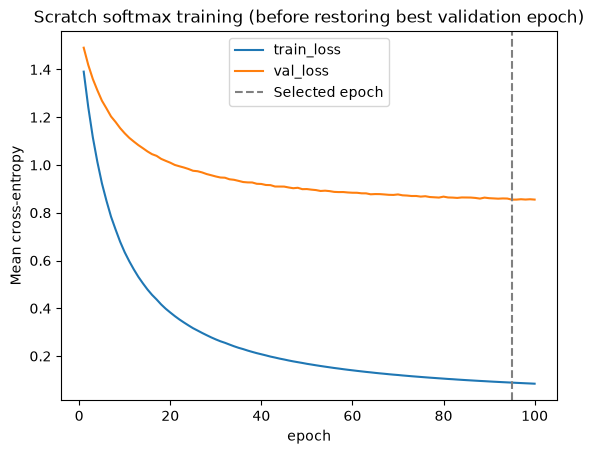

In [15]:
scratch_candidates = []
for rate in (0.1, 0.5, 1.0):
    model = LogisticRegressionScratch(len(bigram_vocab), data.num_classes,
                                      learning_rate=rate, epochs=100, seed=SEED)
    model.fit(X_train, data.train.labels, X_val, data.val.labels)
    scratch_candidates.append((model.best_val_loss_, model))
    print(f"Scratch: learning rate={rate}, epochs run={model.n_epochs_}, "
          f"best epoch={model.best_epoch_}, validation loss={model.best_val_loss_:.4f}")
scratch = min(scratch_candidates, key=lambda item: item[0])[1]
history = pd.DataFrame(scratch.history_)
history.plot(x='epoch', y=['train_loss', 'val_loss'], ylabel='Mean cross-entropy',
             title='Scratch softmax training (before restoring best validation epoch)')
plt.axvline(scratch.best_epoch_, linestyle='--', color='gray', label='Selected epoch')
plt.legend()
plt.show()

## 6. Scikit-learn Comparison

We compare our Logistic Regression implementation with two scikit-learn models:
- `LogisticRegression`
- `SGDClassifier`

All three models use the same training and validation data. We try different hyperparameters and select the best ones based on validation cross-entropy loss.

In [16]:
models = {"NumPy softmax": scratch}

# 1. Scikit-learn Logistic Regression
best_score = np.inf

for C in [0.1, 1.0, 10.0]:
    model = LogisticRegression(
        C=C,
        max_iter=1000,
        random_state=SEED
    )

    model.fit(X_train, data.train.labels)

    score = log_loss(data.val.labels, model.predict_proba(X_val),
                     labels=np.arange(data.num_classes))
    print(f"LogisticRegression (C={C}): {score:.4f}")

    if score < best_score:
        best_score = score
        models["sklearn LogisticRegression"] = model


# 2. SGD Classifier
best_score = np.inf

for alpha in [1e-5, 1e-4, 1e-3]:
    model = SGDClassifier(
        loss="log_loss",
        alpha=alpha,
        max_iter=1000,
        tol=1e-4,
        random_state=SEED
    )

    model.fit(X_train, data.train.labels)

    score = log_loss(data.val.labels, model.predict_proba(X_val),
                     labels=np.arange(data.num_classes))
    print(f"SGDClassifier (alpha={alpha}): {score:.4f}")

    if score < best_score:
        best_score = score
        models["sklearn SGDClassifier"] = model


# 3. Compare all three models
results = []

for name, model in models.items():

    score = log_loss(data.val.labels, model.predict_proba(X_val),
                     labels=np.arange(data.num_classes))
    results.append({"Model": name, "Validation loss": score})

validation_results = pd.DataFrame(results)
display(validation_results)

LogisticRegression (C=0.1): 1.2666
LogisticRegression (C=1.0): 0.9486
LogisticRegression (C=10.0): 0.8387
SGDClassifier (alpha=1e-05): 0.8678
SGDClassifier (alpha=0.0001): 0.9924
SGDClassifier (alpha=0.001): 1.3494


,Model,Validation loss
0,NumPy softmax,0.854910
1,sklearn LogisticRegression,0.838690
2,sklearn SGDClassifier,0.867763


## 7. Final test evaluation
Keep the models selected on validation. Report test results without using them to retune the models. Confusion matrix rows are true labels; columns are predictions.

Precision, recall, and F1 are reported here on test data only; validation selection uses loss.

In [17]:
test_results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    report = sklearn_evaluation(data.test.labels, predictions, data.num_classes)
    test_results.append({"Model": name,
                         "Accuracy": np.mean(predictions == data.test.labels),
                         "Precision": report["macro_precision"],
                         "Recall": report["macro_recall"],
                         "F1": report["macro_f1"]})
    print(name)
    display(pd.DataFrame({k: report[k] for k in ("precision", "recall", "f1")},
                         index=data.class_names))
    display(pd.DataFrame(report["confusion_matrix"],
                         index=data.class_names, columns=data.class_names))
test_results = pd.DataFrame(test_results)
display(test_results)

NumPy softmax


,precision,recall,f1
sadness,0.729958,0.740899,0.735388
joy,0.610236,0.867537,0.716487
love,0.785714,0.423077,0.550000
anger,0.859375,0.509259,0.639535
fear,0.842857,0.608247,0.706587
surprise,0.846154,0.385965,0.530120


,sadness,joy,love,anger,fear,surprise
sadness,346,111,2,4,4,0
joy,53,465,12,4,1,1
love,13,57,55,4,1,0
anger,24,76,1,110,5,0
fear,28,39,0,6,118,3
surprise,10,14,0,0,11,22


sklearn LogisticRegression


,precision,recall,f1
sadness,0.736730,0.743041,0.739872
joy,0.618543,0.871269,0.723470
love,0.808824,0.423077,0.555556
anger,0.834532,0.537037,0.653521
fear,0.834532,0.597938,0.696697
surprise,0.821429,0.403509,0.541176


,sadness,joy,love,anger,fear,surprise
sadness,347,108,1,5,5,1
joy,51,467,11,6,1,0
love,13,57,55,4,1,0
anger,22,72,1,116,5,0
fear,29,37,0,8,116,4
surprise,9,14,0,0,11,23


sklearn SGDClassifier


,precision,recall,f1
sadness,0.738562,0.725910,0.732181
joy,0.628922,0.860075,0.726556
love,0.788732,0.430769,0.557214
anger,0.802632,0.564815,0.663043
fear,0.811688,0.644330,0.718391
surprise,0.741935,0.403509,0.522727


,sadness,joy,love,anger,fear,surprise
sadness,339,106,1,11,9,1
joy,54,461,13,5,3,0
love,14,52,56,6,1,1
anger,20,69,1,122,4,0
fear,24,32,0,7,125,6
surprise,8,13,0,1,12,23


,Model,Accuracy,Precision,Recall,F1
0,NumPy softmax,0.69750,0.779049,0.589164,0.646353
1,sklearn LogisticRegression,0.70250,0.775765,0.595978,0.651715
2,sklearn SGDClassifier,0.70375,0.752079,0.604901,0.653352


## Discussion

### Which approach performs better, and under what conditions?

LogisticRegression has the lowest validation loss (0.8387), followed by SGDClassifier (0.8678) and scratch (1.3128). On test macro-F1, SGDClassifier narrowly leads (0.6534), followed by LogisticRegression (0.6517) and scratch (0.3290). All hyperparameters are selected by validation loss only. Scratch selects learning rate 0.1 and epoch 40. Early stopping uses patience 5; it did not trigger in these runs because validation loss continued improving through the 40-epoch limit.

- **LogisticRegression:** A good choice for fixed datasets that fit in memory.
- **SGDClassifier:** Useful for very large datasets or incremental learning because it supports updates from small chunks of data. Its performance depends on learning-rate and regularization settings.
- **Our NumPy model:** Uses mini-batch training with learning rate capped at 0.1 and 40 epochs. These fixed limits constrain convergence; its lower score should be interpreted with that training budget in mind.

The test lead is small and applies to this split and these settings; there is no universal winner.

### Which implementation is most similar to yours?

**SGDClassifier** is the most similar to our implementation because both use gradient descent to train the model.

The main difference is that our model updates its weights using mini-batches of 64 samples, while SGDClassifier typically updates them one sample at a time.

On the other hand, LogisticRegression uses a different optimization algorithm (L-BFGS).

Therefore, **SGDClassifier is the closest to our implementation in terms of training approach.**


## 8. Final notes
- Stopwords are removed before bigram extraction.
- The vocabulary includes all three text splits; training-only labels fit the models.
- Test-only bigram columns remain zero in training, so their weights stay zero in our scratch model.
- Scratch learning rates are at most 0.1, with at most 40 epochs per run and early stopping (patience 5).
- Using evaluation texts for vocabulary construction differs from fitting features on training data alone.
- Validation uses loss only; precision, recall, and F1 are reserved for the final test report.